In [ ]:
# ============================================================
# ЯЧЕЙКА 1: Установка и импорт библиотек
# ============================================================
# В Google Colab выполнить один раз. В локальной IDE — пропустить.

!pip install -q scikit-learn pandas numpy matplotlib seaborn plotly

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import warnings
import os
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from scipy.cluster.hierarchy import dendrogram, linkage

# Русские подписи на графиках
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print(f"pandas: {pd.__version__}, numpy: {np.__version__}")


pandas: 2.2.3, numpy: 2.1.3


In [ ]:
# ============================================================
# ЯЧЕЙКА 2: Загрузка данных
# ============================================================
# В Colab загрузить 4 файла с исходными данными в пользовательскую папку по умолчанию (/content)
# В локальной IDE положить файлы в рабочую директорию

FILES = {
    # Общий файл
    'general_file': 'marketing_costs.csv',

    # BioGlow / Thread&Trend
    'bioglow_orders': 'orders.csv',
    'bioglow_customers': 'customers.csv',
    'bioglow_products': 'products.csv',
    # BPI Group
    'bpi_projects': 'projects.csv',
    'bpi_clients': 'clients.csv',
    'bpi_services': 'services.csv',
    # PixelPulse
    'pixel_releases': 'releases.csv',
    'pixel_players': 'players.csv',
    'pixel_games': 'games.csv',
}

print("Найденные файлы в рабочей директории:")
for filename in FILES.values():
    if os.path.exists(filename):
        print(f"  {filename}")


Найденные файлы в рабочей директории:
  marketing_costs.csv
  projects.csv
  clients.csv
  services.csv


In [ ]:

# ============================================================
# ЯЧЕЙКА 3: CONFIG — настройки под каждый кейс
# ============================================================

CONFIG = {

    # ---------- КЕЙС 1: BioGlow ----------
    'bioglow': {
        'name': 'BioGlow (косметика, D2C + B2B)',
        'facts': 'orders.csv',
        'entities': 'customers.csv',
        'ref': 'products.csv',
        'date_col': 'sale_date',
        'id_col': 'order_id',
        'entity_col': 'customer_id',
        'ref_col': 'product_id',
        'amount': lambda df: df['sales_price'] * df['quantity'],
        'cost':   lambda df: df['production_cost'] * df['quantity'],
        'extras_entity': ['customer_type', 'region', 'acquisition_channel'],
        'extras_ref':    ['category'],
        'churn_days': 90,
        'segment_names': {
            'high_high_recent': 'VIP-клиенты (чемпионы)',
            'high_low_recent':  'VIP в зоне риска',
            'recent_new':       'Новые перспективные',
            'frequent':         'Лояльные',
            'stale':            'Спящие и потерянные',
            'default':          'Требуют внимания',
        },
    },

    # ---------- КЕЙС 2: Thread&Trend ----------
    'threadtrend': {
        'name': 'Thread&Trend (мода, D2C + B2B)',
        'facts': 'orders.csv',
        'entities': 'customers.csv',
        'ref': 'products.csv',
        'date_col': 'sale_date',
        'id_col': 'order_id',
        'entity_col': 'customer_id',
        'ref_col': 'product_id',
        'amount': lambda df: df['sales_price'] * df['quantity'] * (1 - df['returned']),
        'cost':   lambda df: df['production_cost'] * df['quantity'] * (1 - df['returned']),
        'extras_entity': ['customer_type', 'region', 'acquisition_channel'],
        'extras_ref':    ['category'],
        'churn_days': 180,
        'segment_names': {
            'high_high_recent': 'VIP-покупатели',
            'high_low_recent':  'Спящие VIP (риск ухода)',
            'recent_new':       'Новички',
            'frequent':         'Лояльные',
            'stale':            'Потерянные',
            'default':          'Требуют внимания',
        },
    },

    # ---------- КЕЙС 3: BPI Group ----------
    'bpigroup': {
        'name': 'BPI Group (B2B-консалтинг)',
        'facts': 'projects.csv',
        'entities': 'clients.csv',
        'ref': 'services.csv',
        'date_col': 'start_date',
        'id_col': 'project_id',
        'entity_col': 'client_id',
        'ref_col': 'service_id',
        'amount': lambda df: df['contract_value'],
        'cost':   lambda df: df['standard_cost'],
        'extras_entity': ['industry', 'company_size', 'revenue_segment', 'acquisition_channel'],
        'extras_ref':    ['practice'],
        'churn_days': 365,
        'segment_names': {
            'high_high_recent': 'Ключевые клиенты (KAM)',
            'high_low_recent':  'Спящие ключевые клиенты',
            'recent_new':       'Новые клиенты',
            'frequent':         'Повторные (высокий LTV)',
            'stale':            'Потерянные клиенты',
            'default':          'На развитии',
        },
    },

    # ---------- КЕЙС 4: PixelPulse Games ----------
    'pixelpulse': {
        'name': 'PixelPulse Games (мобильные игры)',
        'facts': 'releases.csv',
        'entities': 'players.csv',
        'ref': 'games.csv',
        'date_col': 'event_date',
        'id_col': 'transaction_id',
        'entity_col': 'player_id',
        'ref_col': 'game_id',
        'amount': lambda df: df['amount_usd'],
        'cost':   lambda df: 0.0,
        'extras_entity': ['player_type', 'platform', 'country', 'ltv_segment', 'acquisition_channel'],
        'extras_ref':    ['genre', 'monetization_model'],
        'churn_days': 30,
        'segment_names': {
            'high_high_recent': 'Активные киты',
            'high_low_recent':  'Спящие киты',
            'recent_new':       'Новички',
            'frequent':         'Лояльные платящие',
            'stale':            'Отток (churned)',
            'default':          'F2P-актив',
        },
    },
}

# Словарь перевода технических имён признаков в русские подписи
FEATURE_LABELS = {
    'recency':          'Давность покупки (дней)',
    'frequency':        'Частота заказов',
    'monetary':         'Сумма покупок',
    'avg_check':        'Средний чек',
    'margin_pct':       'Маржинальность',
    'orders_per_month': 'Заказов в месяц',
    'total_items':      'Всего позиций',
    'n_categories':     'Разнообразие категорий',
    'recency_log':      'Давность (лог)',
    'frequency_log':    'Частота (лог)',
    'monetary_log':     'Сумма покупок (лог)',
    'avg_check_log':    'Средний чек (лог)',
    'total_items_log':  'Всего позиций (лог)',
    'n_categories_log': 'Категории (лог)',
    'orders_per_month_log': 'Заказов/мес (лог)',
    'margin_pct_log':   'Маржа (лог)',
    'pca1':             'Главная компонента 1',
    'pca2':             'Главная компонента 2',
    'tsne1':            't-SNE ось 1',
    'tsne2':            't-SNE ось 2',
}

# >>> ВЫБЕРИТЕ КЕЙС ЗДЕСЬ <<<
CASE = 'bioglow'   # 'bioglow' | 'threadtrend' | 'bpigroup' | 'pixelpulse'


cfg = CONFIG[CASE]
print(f" Выбран кейс: {cfg['name']}")


 Выбран кейс: BioGlow (косметика, D2C + B2B)


In [ ]:
# ============================================================
# ЯЧЕЙКА 4: load_and_enrich — автоматическое определение кейса и загрузка
# ============================================================

# Проверяем, какие файлы реально есть на диске, и при необходимости корректируем CONFIG
for case_key, case_cfg in CONFIG.items():
    if os.path.exists(case_cfg['facts']) and os.path.exists(case_cfg['entities']) and os.path.exists(case_cfg['ref']):
        if CASE != case_key:
            print(f"ℹ️ Автоматически переключаем кейс с '{CASE}' на '{case_key}', так как найдены соответствующие файлы.")
            CASE = case_key
            cfg = CONFIG[CASE]
        break

def load_and_enrich(cfg):
    if not (os.path.exists(cfg['facts']) and os.path.exists(cfg['entities']) and os.path.exists(cfg['ref'])):
        raise FileNotFoundError(
            f"Не найдены файлы для кейса '{cfg['name']}'! "
            f"Ожидались: {cfg['facts']}, {cfg['entities']}, {cfg['ref']}\n"
            f"Пожалуйста, загрузите их или убедитесь в правильности выбора кейса."
        )

    facts    = pd.read_csv(cfg['facts'], parse_dates=[cfg['date_col']])
    entities = pd.read_csv(cfg['entities'])
    ref      = pd.read_csv(cfg['ref'])

    ref_cols = [cfg['ref_col']] + cfg['extras_ref']
    for cost_col in ['production_cost', 'standard_cost']:
        if cost_col in ref.columns:
            ref_cols.append(cost_col)
            break

    ent_cols = [cfg['entity_col']] + cfg['extras_entity']

    df = facts.merge(ref[list(dict.fromkeys(ref_cols))], on=cfg['ref_col'], how='left')
    df = df.merge(entities[ent_cols], on=cfg['entity_col'], how='left')

    df['_amount'] = cfg['amount'](df)
    df['_cost']   = cfg['cost'](df)
    df['_margin'] = df['_amount'] - df['_cost']

    print(f"✅ Успешно загружен кейс: {cfg['name']}")
    print(f" Загружено строк: {len(df)}")
    print(f"   Уникальных клиентов ({cfg['entity_col']}): {df[cfg['entity_col']].nunique()}")
    print(f"   Период: {df[cfg['date_col']].min().date()} — {df[cfg['date_col']].max().date()}")
    print(f"   Сумма выручки: {df['_amount'].sum():,.0f}")
    print(f"   Сумма маржи:   {df['_margin'].sum():,.0f}")
    return df

df = load_and_enrich(cfg)
print("\nПервые 5 строк:")
df.head()

✅ Успешно загружен кейс: BPI Group (B2B-консалтинг)
 Загружено строк: 100
   Уникальных клиентов (client_id): 50
   Период: 2025-01-08 — 2026-01-08
   Сумма выручки: 43,258,000
   Сумма маржи:   9,628,000

Первые 5 строк:


,project_id,service_id,client_id,start_date,channel_id,campaign_id,contract_value,planned_hours,actual_hours,scope_creep,...,on_time,practice,standard_cost,industry,company_size,revenue_segment,acquisition_channel,_amount,_cost,_margin
0,PR0001,S001,C0001,2025-01-08,CH1,CH1_2025-01,640000.0,320,340,0,...,1,СМК,420000.0,Ритейл,Large,100M+,Direct Sales,640000.0,420000.0,220000.0
1,PR0002,S011,C0002,2025-01-12,CH3,CH3_2025-01,780000.0,400,470,1,...,0,Digital,520000.0,Производство,Large,100M+,Partners & Referral,780000.0,520000.0,260000.0
2,PR0003,S004,C0003,2025-01-15,CH1,CH1_2025-01,280000.0,240,310,1,...,0,Нормирование,260000.0,IT,Medium,10-100M,Direct Sales,280000.0,260000.0,20000.0
3,PR0004,S009,C0004,2025-01-20,CH2,CH2_2025-01,340000.0,220,225,0,...,1,HR,310000.0,Ритейл,SME,<10M,Tender/RFP,340000.0,310000.0,30000.0
4,PR0005,S012,C0005,2025-01-24,CH3,CH3_2025-01,920000.0,380,410,0,...,1,Digital,610000.0,Производство,Medium,10-100M,Partners & Referral,920000.0,610000.0,310000.0


In [ ]:
# ============================================================
# ЯЧЕЙКА 5: Расчет метрик RFM
# ============================================================

def calculate_rfm(df, cfg):
    # Вычисляем дату последнего события в датасете в качестве опорной точки
    max_date = df[cfg['date_col']].max()

    # Агрегируем данные по клиентам
    rfm = df.groupby(cfg['entity_col']).agg(
        recency      = (cfg['date_col'], lambda x: (max_date - x.max()).days),
        frequency    = (cfg['id_col'], 'nunique'),
        monetary     = ('_amount', 'sum'),
        margin       = ('_margin', 'sum'),
        total_items  = (cfg['id_col'], 'count')  # в B2B проектах количество совпадает с частотой
    )

    # Дополнительные метрики
    rfm['avg_check'] = rfm['monetary'] / rfm['frequency']
    rfm['margin_pct'] = rfm['margin'] / rfm['monetary'].replace(0, np.nan)
    rfm['margin_pct'] = rfm['margin_pct'].fillna(0)

    # Среднее число заказов в месяц (упрощенно на основе времени активности)
    days_active = df.groupby(cfg['entity_col'])[cfg['date_col']].agg(lambda x: max((x.max() - x.min()).days, 1))
    rfm['orders_per_month'] = (rfm['frequency'] / (days_active / 30.4)).clip(lower=0.1)

    # Расчет скоринга (процентили 1-5)
    # Recency: чем меньше дней с последней покупки, тем лучше (скор выше)
    rfm['R_score'] = pd.qcut(rfm['recency'].rank(method='first'), q=5, labels=[5, 4, 3, 2, 1]).astype(int)
    # Frequency и Monetary: чем больше, тем лучше (скор выше)
    rfm['F_score'] = pd.qcut(rfm['frequency'].rank(method='first'), q=5, labels=[1, 2, 3, 4, 5]).astype(int)
    rfm['M_score'] = pd.qcut(rfm['monetary'].rank(method='first'), q=5, labels=[1, 2, 3, 4, 5]).astype(int)

    rfm['RFM_combo'] = rfm['R_score'].astype(str) + rfm['F_score'].astype(str) + rfm['M_score'].astype(str)

    # Присоединяем дополнительные характеристики клиентов
    entities_df = df[[cfg['entity_col']] + cfg['extras_entity']].drop_duplicates(subset=[cfg['entity_col']]).set_index(cfg['entity_col'])
    rfm = rfm.join(entities_df, how='left')

    return rfm

rfm = calculate_rfm(df, cfg)
print(f"✅ RFM-метрики рассчитаны для {len(rfm)} клиентов.")
rfm.head()

✅ RFM-метрики рассчитаны для 50 клиентов.


,recency,frequency,monetary,margin,total_items,avg_check,margin_pct,orders_per_month,R_score,F_score,M_score,RFM_combo,industry,company_size,revenue_segment,acquisition_channel
client_id,,,,,,,,,,,,,,,,
C0001,178,2,945000.0,245000.0,2,472500.0,0.259259,0.325134,1,1,3,113,Ритейл,Large,100M+,Direct Sales
C0002,175,2,1142000.0,282000.0,2,571000.0,0.246935,0.326882,1,1,4,114,Производство,Large,100M+,Partners & Referral
C0003,171,2,478000.0,28000.0,2,239000.0,0.058577,0.325134,1,1,1,111,IT,Medium,10-100M,Direct Sales
C0004,168,2,638000.0,38000.0,2,319000.0,0.059561,0.328649,1,1,2,112,Ритейл,SME,<10M,Tender/RFP
C0005,164,2,1155000.0,325000.0,2,577500.0,0.281385,0.328649,1,1,5,115,Производство,Medium,10-100M,Partners & Referral


In [ ]:


# ============================================================
# ЯЧЕЙКА 6: assign_segment — бизнес-сегменты по RFM
# ============================================================
# Правила на основе средних значений (устойчиво к разным масштабам).

def assign_segment(rfm, cfg):
    g_mean = rfm[['recency', 'frequency', 'monetary']].mean()

    def seg(row):
        if row['monetary'] > g_mean['monetary'] * 1.5 and row['recency'] < g_mean['recency'] * 0.8:
            return cfg['segment_names']['high_high_recent']
        if row['monetary'] > g_mean['monetary'] * 1.5 and row['recency'] >= g_mean['recency']:
            return cfg['segment_names']['high_low_recent']
        if row['recency'] < g_mean['recency'] * 0.6 and row['frequency'] < g_mean['frequency']:
            return cfg['segment_names']['recent_new']
        if row['frequency'] > g_mean['frequency'] * 1.3:
            return cfg['segment_names']['frequent']
        if row['recency'] > g_mean['recency'] * 1.5:
            return cfg['segment_names']['stale']
        return cfg['segment_names']['default']

    rfm['segment'] = rfm.apply(seg, axis=1)
    return rfm


rfm = assign_segment(rfm, cfg)
print(" Сегментация выполнена")
print("\nРаспределение клиентов по RFM-сегментам:")
print(rfm['segment'].value_counts())


 Сегментация выполнена

Распределение клиентов по RFM-сегментам:
segment
На развитии           38
Потерянные клиенты    12
Name: count, dtype: int64


In [ ]:
# ============================================================
# ЯЧЕЙКА 7: clusterize — признаки, масштабирование, выбор k
# ============================================================
# Признаки: RFM + средний чек + маржинальность + заказов/мес + позиции.
# Логарифмируем monetary и avg_check, чтобы сгладить выбросы из-за «китов» - клиентов с большим средничм чеком
# k выбираем по максимуму силуэта на диапазоне 2..10.

def clusterize(rfm, k_range=range(2, 11)):
    feats = ['recency', 'frequency', 'monetary', 'avg_check',
             'margin_pct', 'orders_per_month', 'total_items']
    if 'n_categories' in rfm.columns:
        feats.append('n_categories')

    # Создаем временные копии для логарифмирования без модификации исходного rfm на лету
    rfm_feats = rfm.copy()
    for col in ['monetary', 'avg_check']:
        rfm_feats[f'{col}_log'] = np.log1p(rfm_feats[col].clip(lower=0))
        if f'{col}_log' not in feats:
            feats.append(f'{col}_log')

    X = rfm_feats[feats].fillna(0)
    Xs = StandardScaler().fit_transform(X)
    Xs_df = pd.DataFrame(Xs, columns=X.columns, index=rfm.index)

    inertias, sils, chs, dbs = [], [], [], []
    for k in k_range:
        km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
        lab = km.fit_predict(Xs_df)
        inertias.append(km.inertia_)
        sils.append(silhouette_score(Xs_df, lab))
        chs.append(calinski_harabasz_score(Xs_df, lab))
        dbs.append(davies_bouldin_score(Xs_df, lab))

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle(f'Выбор оптимального числа кластеров — {cfg["name"]}', fontsize=14)
    axes[0,0].plot(k_range, inertias, 'bo-'); axes[0,0].set_title('Метод локтя')
    axes[0,1].plot(k_range, sils,     'ro-'); axes[0,1].set_title('Коэффициент силуэта')
    axes[1,0].plot(k_range, chs,      'go-'); axes[1,0].set_title('Индекс Калински-Харабаша')
    axes[1,1].plot(k_range, dbs,      'mo-'); axes[1,1].set_title('Индекс Дэвиса-Болдина')
    for ax in axes.flat:
        ax.set_xlabel('Число кластеров (k)')
        ax.grid(alpha=.3)
    axes[0,0].set_ylabel('Инерция')
    axes[0,1].set_ylabel('Силуэт')
    axes[1,0].set_ylabel('CH-индекс')
    axes[1,1].set_ylabel('DB-индекс')
    plt.tight_layout(); plt.show()

    optimal_k = list(k_range)[int(np.argmax(sils))]
    print(f" Оптимальное k = {optimal_k} (коэффициент силуэта = {max(sils):.3f})")

    rfm['cluster'] = KMeans(n_clusters=optimal_k,
                            random_state=RANDOM_STATE, n_init=10).fit_predict(Xs_df)

    agglo = AgglomerativeClustering(n_clusters=optimal_k, linkage='ward')
    rfm['cluster_agglo'] = agglo.fit_predict(Xs_df)

    dbscan = DBSCAN(eps=0.7, min_samples=5)
    rfm['cluster_dbscan'] = dbscan.fit_predict(Xs_df)

    print("\nСравнение алгоритмов кластеризации:")
    for name, labels in [('K-средних', rfm['cluster']),
                         ('Агломеративная', rfm['cluster_agglo']),
                         ('DBSCAN', rfm['cluster_dbscan'])]:
        mask = labels != -1
        if mask.sum() < 2 or len(set(labels[mask])) < 2:
            print(f"  {name}: недостаточно кластеров")
            continue
        print(f"  {name}: силуэт={silhouette_score(Xs_df[mask], labels[mask]):.3f}, "
              f"CH={calinski_harabasz_score(Xs_df[mask], labels[mask]):.1f}, "
              f"DB={davies_bouldin_score(Xs_df[mask], labels[mask]):.3f}, "
              f"кластеров={len(set(labels[mask]))}")

    return rfm, Xs_df, optimal_k, max(sils)

rfm, Xs_df, optimal_k, best_sil = clusterize(rfm)

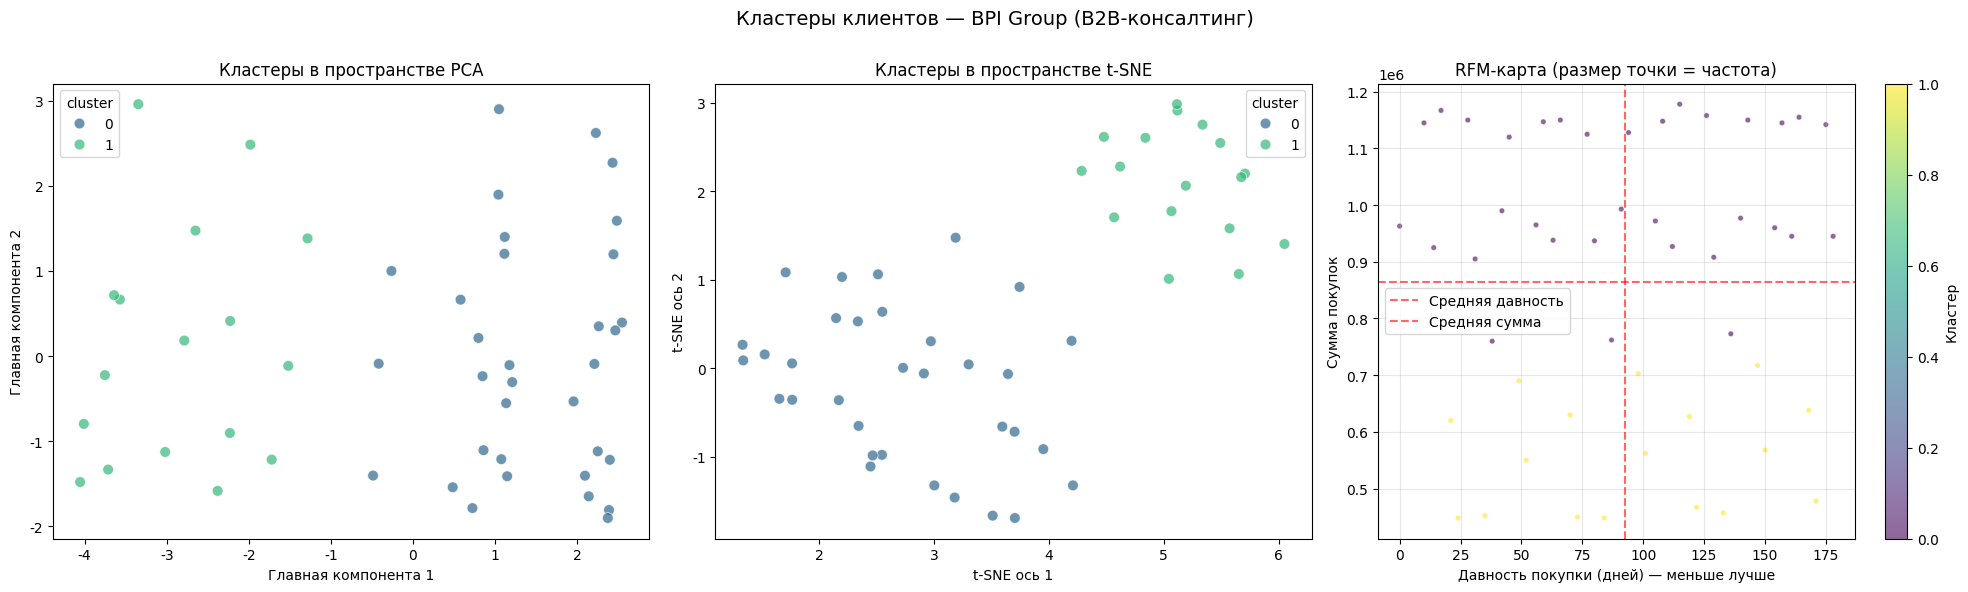

In [ ]:

# ============================================================
# ЯЧЕЙКА 8: visualize — PCA, t-SNE, RFM-карта
# ============================================================

def visualize(rfm, Xs_df, cfg):
    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    pcs = pca.fit_transform(Xs_df)
    rfm['pca1'], rfm['pca2'] = pcs[:, 0], pcs[:, 1]

    tsne = TSNE(n_components=2, random_state=RANDOM_STATE,
                perplexity=min(30, len(rfm) - 1))
    ts = tsne.fit_transform(Xs_df)
    rfm['tsne1'], rfm['tsne2'] = ts[:, 0], ts[:, 1]

    fig, axes = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(f'Кластеры клиентов — {cfg["name"]}', fontsize=14)

    sns.scatterplot(x='pca1', y='pca2', hue='cluster', data=rfm,
                    palette='viridis', ax=axes[0], s=60, alpha=.7)
    axes[0].set_title('Кластеры в пространстве PCA')
    axes[0].set_xlabel('Главная компонента 1')
    axes[0].set_ylabel('Главная компонента 2')

    sns.scatterplot(x='tsne1', y='tsne2', hue='cluster', data=rfm,
                    palette='viridis', ax=axes[1], s=60, alpha=.7)
    axes[1].set_title('Кластеры в пространстве t-SNE')
    axes[1].set_xlabel('t-SNE ось 1')
    axes[1].set_ylabel('t-SNE ось 2')

    sc = axes[2].scatter(rfm['recency'], rfm['monetary'],
                         s=rfm['frequency'] * 8, c=rfm['cluster'],
                         cmap='viridis', alpha=.6, edgecolor='white', linewidth=.5)
    axes[2].axvline(rfm['recency'].mean(), color='red', ls='--', alpha=.6,
                    label='Средняя давность')
    axes[2].axhline(rfm['monetary'].mean(), color='red', ls='--', alpha=.6,
                    label='Средняя сумма')
    axes[2].set_xlabel('Давность покупки (дней) — меньше лучше')
    axes[2].set_ylabel('Сумма покупок')
    axes[2].set_title('RFM-карта (размер точки = частота)')
    axes[2].legend()
    axes[2].grid(alpha=.3)
    plt.colorbar(sc, ax=axes[2], label='Кластер')

    plt.tight_layout(); plt.show()
    return rfm


rfm = visualize(rfm, Xs_df, cfg)


In [ ]:
# ============================================================
# ЯЧЕЙКА 9: profile_clusters — сводная таблица по кластерам
# ============================================================
# profile хранит английские имена колонок.
# Русские подписи — только для вывода (PROFILE_RU).

PROFILE_RU = {
    'n_clients':  'Клиентов',
    'recency':    'Ср. давность (дн)',
    'frequency':  'Ср. частота',
    'monetary':   'Ср. сумма',
    'avg_check':  'Ср. чек',
    'margin_pct': 'Маржа, %',
    'R_score':    'R-скоринг',
    'F_score':    'F-скоринг',
    'M_score':    'M-скоринг',
    'churn_rate': 'Доля оттока',
}


def profile_clusters(rfm, cfg):
    entity_col = cfg['entity_col']

    # Сбрасываем индекс, чтобы колонка ID клиента гарантированно присутствовала как колонка
    rfm_reset = rfm.reset_index()

    prof = rfm_reset.groupby('cluster').agg(
        n_clients  = (entity_col, 'count'),
        recency    = ('recency', 'mean'),
        frequency  = ('frequency', 'mean'),
        monetary   = ('monetary', 'mean'),
        avg_check  = ('avg_check', 'mean'),
        margin_pct = ('margin_pct', 'mean'),
        R_score    = ('R_score', 'mean'),
        F_score    = ('F_score', 'mean'),
        M_score    = ('M_score', 'mean'),
        churn_rate = ('recency', lambda x: (x > cfg['churn_days']).mean()),
    ).round(2).sort_values('monetary', ascending=False)

    return prof  # ← английские имена, БЕЗ rename


profile = profile_clusters(rfm, cfg)

print(" Профиль кластеров:")
print(profile.rename(columns=PROFILE_RU))

for extra in cfg['extras_entity'][:2]:
    print(f"\nРаспределение «{extra}» по кластерам (%):")
    print(pd.crosstab(rfm['cluster'], rfm[extra], normalize='index').round(2))

 Профиль кластеров:
         Клиентов  Ср. давность (дн)  Ср. частота   Ср. сумма    Ср. чек  \
cluster                                                                    
0              33              90.94          2.0  1022818.18  511409.09   
1              17              95.12          2.0   559117.65  279558.82   

         Маржа, %  R-скоринг  F-скоринг  M-скоринг  Доля оттока  
cluster                                                          
0            0.27       3.03       3.03       3.82          0.0  
1            0.05       2.94       2.94       1.41          0.0  

Распределение «industry» по кластерам (%):
industry    IT  Производство  Ритейл  Финансы
cluster                                      
0         0.18          0.36    0.21     0.24
1         0.41          0.12    0.35     0.12

Распределение «company_size» по кластерам (%):
company_size  Large  Medium   SME
cluster                          
0              0.39    0.45  0.15
1              0.18    0.41  0.41

In [ ]:

# ============================================================
# ЯЧЕЙКА 10: interpret — названия кластеров + стратегии
# ============================================================
# обращаемся к row по АНГЛИЙСКИМ именам (как в profile)

def interpret_cluster(row, g_mean, cfg):
    if row['monetary'] > g_mean['monetary'] * 1.5 and row['recency'] < g_mean['recency'] * 0.8:
        return (cfg['segment_names']['high_high_recent'],
                'Персональный менеджер, эксклюзивные офферы, ранний доступ, максимальный уровень лояльности')
    if row['monetary'] > g_mean['monetary'] * 1.5 and row['recency'] >= g_mean['recency']:
        return (cfg['segment_names']['high_low_recent'],
                'Реактивация: персональное письмо + скидка 15–20%, опрос причин ухода, возврат через личный контакт')
    if row['recency'] < g_mean['recency'] * 0.6 and row['frequency'] < g_mean['frequency']:
        return (cfg['segment_names']['recent_new'],
                'Onboarding-цепочка, welcome-серия, обучение продукту, стимул ко 2-й покупке в течение 30 дней')
    if row['frequency'] > g_mean['frequency'] * 1.3:
        return (cfg['segment_names']['frequent'],
                'Кросс-продажи по категориям, бандлы со скидкой, реферальная программа')
    if row['recency'] > g_mean['recency'] * 1.5:
        return (cfg['segment_names']['stale'],
                'Win-back с агрессивной скидкой один раз; если нет реакции — исключить из активных рассылок')
    return (cfg['segment_names']['default'],
            'A/B-тест офферов, сегментированные письма по последней покупке')


g_mean = rfm[['recency', 'frequency', 'monetary']].mean()
cluster_info = {}
for cid, row in profile.iterrows():
    name, strategy = interpret_cluster(row, g_mean, cfg)
    cluster_info[cid] = {'name': name, 'strategy': strategy}

print("=" * 80)
print(f"ИНТЕРПРЕТАЦИЯ КЛАСТЕРОВ — {cfg['name']}")
print("=" * 80)
for cid, row in profile.iterrows():
    info = cluster_info[cid]
    print(f"\nКластер {cid}: {info['name']}")
    print(f"  Клиентов:              {int(row['n_clients'])}")
    print(f"  Средняя давность:      {row['recency']:.0f} дней")
    print(f"  Средняя частота:       {row['frequency']:.1f}")
    print(f"  Средняя сумма:         {row['monetary']:,.0f}")
    print(f"  Средний чек:           {row['avg_check']:,.0f}")
    print(f"  Маржинальность:        {row['margin_pct']*100:.1f}%")
    print(f"  Доля оттока ({cfg['churn_days']}+ дн): {row['churn_rate']*100:.1f}%")
    print(f"  Стратегия:             {info['strategy']}")


ИНТЕРПРЕТАЦИЯ КЛАСТЕРОВ — BPI Group (B2B-консалтинг)

Кластер 0: На развитии
  Клиентов:              33
  Средняя давность:      91 дней
  Средняя частота:       2.0
  Средняя сумма:         1,022,818
  Средний чек:           511,409
  Маржинальность:        27.0%
  Доля оттока (365+ дн): 0.0%
  Стратегия:             A/B-тест офферов, сегментированные письма по последней покупке

Кластер 1: На развитии
  Клиентов:              17
  Средняя давность:      95 дней
  Средняя частота:       2.0
  Средняя сумма:         559,118
  Средний чек:           279,559
  Маржинальность:        5.0%
  Доля оттока (365+ дн): 0.0%
  Стратегия:             A/B-тест офферов, сегментированные письма по последней покупке


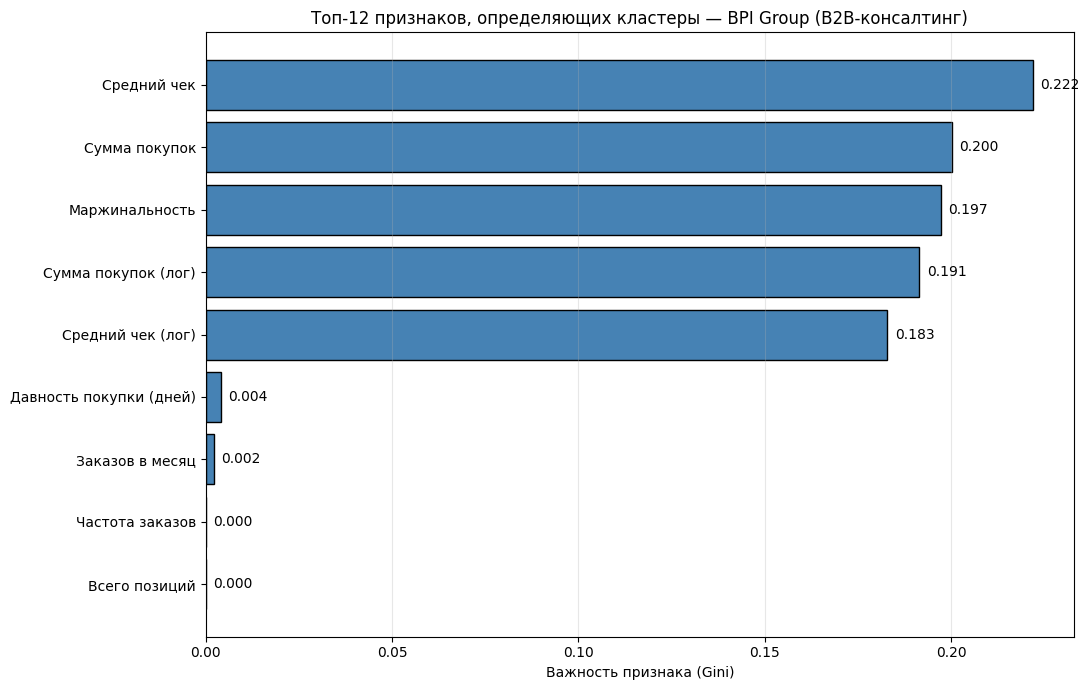


Топ-10 признаков:
             feature_ru     gini  permutation
            Средний чек 0.221872          0.0
          Сумма покупок 0.200236          0.0
         Маржинальность 0.197311          0.0
    Сумма покупок (лог) 0.191471          0.0
      Средний чек (лог) 0.182875          0.0
Давность покупки (дней) 0.004039          0.0
        Заказов в месяц 0.002197          0.0
        Частота заказов 0.000000          0.0
          Всего позиций 0.000000          0.0


In [ ]:

# ============================================================
# ЯЧЕЙКА 11: feature_importance — какие признаки «разделяют» кластеры
# ============================================================

def feature_importance(Xs_df, labels):
    rf = RandomForestClassifier(n_estimators=200,
                                random_state=RANDOM_STATE, n_jobs=-1)
    rf.fit(Xs_df, labels)
    imp = pd.DataFrame({
        'feature': Xs_df.columns,
        'gini': rf.feature_importances_
    })
    perm = permutation_importance(rf, Xs_df, labels, n_repeats=10,
                                  random_state=RANDOM_STATE, n_jobs=-1)
    imp['permutation'] = perm.importances_mean
    imp['feature_ru'] = imp['feature'].map(FEATURE_LABELS).fillna(imp['feature'])
    return imp.sort_values('gini', ascending=False)


imp = feature_importance(Xs_df, rfm['cluster'])

fig, ax = plt.subplots(figsize=(11, 7))
top = imp.head(12)
ax.barh(top['feature_ru'], top['gini'], color='steelblue', edgecolor='black')
ax.set_xlabel('Важность признака (Gini)')
ax.set_title(f'Топ-12 признаков, определяющих кластеры — {cfg["name"]}')
ax.grid(alpha=.3, axis='x')
for i, v in enumerate(top['gini']):
    ax.text(v + 0.002, i, f'{v:.3f}', va='center')
plt.gca().invert_yaxis()
plt.tight_layout(); plt.show()

print("\nТоп-10 признаков:")
print(imp[['feature_ru', 'gini', 'permutation']].head(10).to_string(index=False))


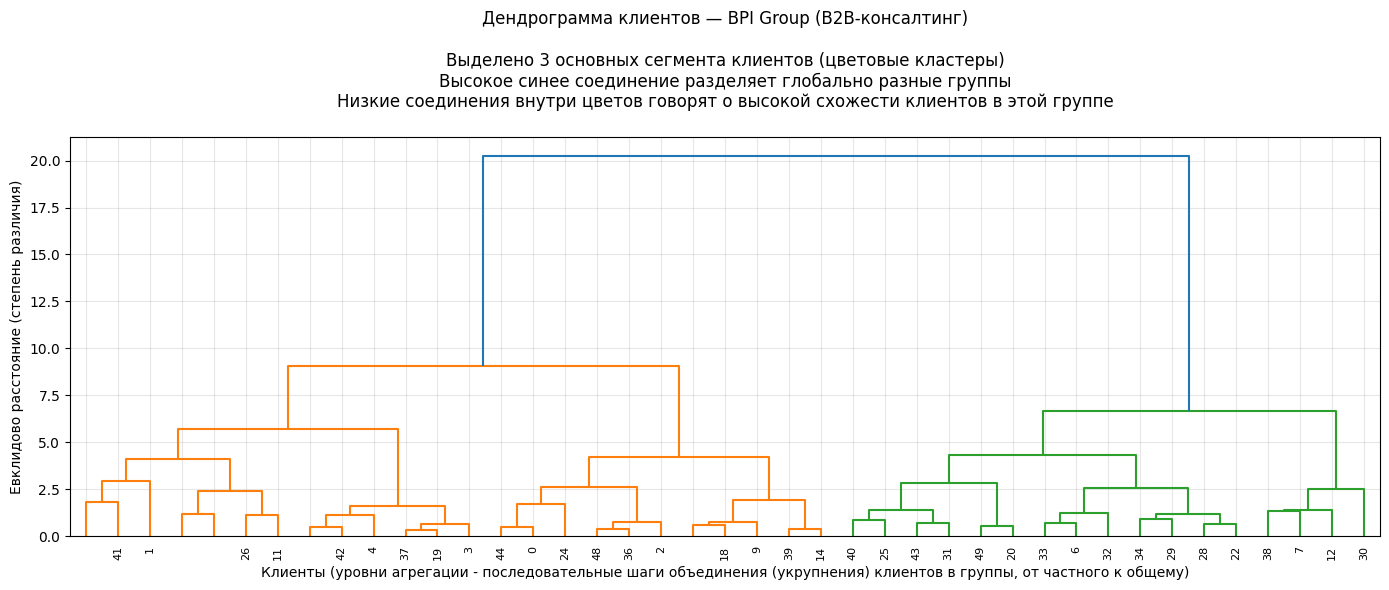

In [ ]:

# ============================================================
# ЯЧЕЙКА 12: дендрограмма (на выборке, для читаемости)
# ============================================================

sample_size = min(150, len(Xs_df))
sample_idx = np.random.choice(len(Xs_df), sample_size, replace=False)
X_sample = Xs_df.iloc[sample_idx]

linked = linkage(X_sample, method='ward')

fig, ax = plt.subplots(figsize=(14, 6))
dendrogram(linked, orientation='top', distance_sort='descending',
           show_leaf_counts=False, ax=ax,
           truncate_mode='level', p=5)

# Заголовок графика с переносом строки и выводом главного инсайта
ax.set_title(f'Дендрограмма клиентов — {cfg["name"]}\n\n'
             f'Выделено 3 основных сегмента клиентов (цветовые кластеры)\n'
             f'Высокое синее соединение разделяет глобально разные группы\n'
             f'Низкие соединения внутри цветов говорят о высокой схожести клиентов в этой группе\n')

ax.set_xlabel('Клиенты (уровни агрегации - последовательные шаги объединения (укрупнения) клиентов в группы, от частного к общему)')
ax.set_ylabel('Евклидово расстояние (степень различия)')
ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

In [ ]:


# ============================================================
# ЯЧЕЙКА 13: сохранение RFM-таблицы и профилей кластеров
# ============================================================

out_cols = [cfg['entity_col']] + cfg['extras_entity'] + [
    'recency', 'frequency', 'monetary', 'avg_check', 'margin_pct',
    'total_items', 'R_score', 'F_score', 'M_score',
    'RFM_combo', 'segment', 'cluster'
]
if 'n_categories' in rfm.columns:
    out_cols.insert(-1, 'n_categories')
out_cols = [c for c in out_cols if c in rfm.columns]

rfm[out_cols].to_csv(f'{CASE}_rfm_clusters.csv', index=False)
profile.to_csv(f'{CASE}_cluster_profiles.csv')

print(f" Сохранено:")
print(f"   {CASE}_rfm_clusters.csv — {len(rfm)} клиентов")
print(f"   {CASE}_cluster_profiles.csv — {len(profile)} кластеров")


 Сохранено:
   bpigroup_rfm_clusters.csv — 50 клиентов
   bpigroup_cluster_profiles.csv — 2 кластеров


In [ ]:


# ============================================================
# ЯЧЕЙКА 14: итоговая сводка по кейсу
# ============================================================

print("=" * 80)
print(f"ИТОГИ RFM-КЛАСТЕРИЗАЦИИ — {cfg['name']}")
print("=" * 80)
print(f"Клиентов:                   {len(rfm)}")
print(f"Кластеров:                  {optimal_k}")
print(f"Коэффициент силуэта:        {best_sil:.3f}")
print(f"Средний чек:                {rfm['avg_check'].mean():,.0f}")
print(f"Средняя давность покупки:   {rfm['recency'].mean():.0f} дней")
print(f"Доля оттока ({cfg['churn_days']}+ дн):    {(rfm['recency'] > cfg['churn_days']).mean()*100:.1f}%")
print(f"Суммарная выручка:          {rfm['monetary'].sum():,.0f}")
print(f"Суммарная маржа:            {rfm['margin'].sum():,.0f}")
print("\nРаспределение по RFM-сегментам:")
print(rfm['segment'].value_counts().to_string())

print("\nСводка по кластерам:")
for cid in sorted(profile.index):
    info = cluster_info[cid]
    n  = int(profile.loc[cid, 'n_clients'])
    m  = profile.loc[cid, 'monetary']
    print(f"  Кластер {cid} → {info['name']:32s} | "
          f"клиентов: {n:4d} | средняя сумма: {m:>10,.0f}")
print("=" * 80)



ИТОГИ RFM-КЛАСТЕРИЗАЦИИ — BPI Group (B2B-консалтинг)
Клиентов:                   50
Кластеров:                  2
Коэффициент силуэта:        0.514
Средний чек:                432,580
Средняя давность покупки:   92 дней
Доля оттока (365+ дн):    0.0%
Суммарная выручка:          43,258,000
Суммарная маржа:            9,628,000

Распределение по RFM-сегментам:
segment
На развитии           38
Потерянные клиенты    12

Сводка по кластерам:
  Кластер 0 → На развитии                      | клиентов:   33 | средняя сумма:  1,022,818
  Кластер 1 → На развитии                      | клиентов:   17 | средняя сумма:    559,118
